# TP 1 – Vision artificielle (Master 2 GNIPIA)
Code des activités 1 à 6. Placez `image_exemple.jpg` dans le même dossier que ce notebook, sinon une image de synthèse est générée automatiquement.

In [3]:
%pip install opencv-python numpy matplotlib

  Using cached opencv_python-5.1.0.95-cp37-abi3-win_amd64.whl.metadata (21 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
Using cached opencv_python-5.1.0.95-cp37-abi3-win_amd64.whl (48.0 MB)
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
    --------------------------------------- 0.3/12.7 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.7 MB 1.2 MB/s eta 0:00:11
   -- ------------------------------------- 0.8/12.7 MB 1.2 MB/s eta 0:00:10
   --- ------------------------------------ 1.0/12.7 MB 1.2 MB/s eta 0:00:10
   ---- ----------------------------------- 1.3/12.7 MB 1.3 MB/s eta 0:00:10
   ----- ---------------------------------- 1.8/12.7 MB 1.4 MB/s eta 0:00:08
   ------ --------------------------------- 2.1/12.7 MB 1.5 MB/s eta 0:00:08
   -------- ------------------------------- 2.6/12.7 MB 1.6 MB/s eta 0:00:07
   --------- ------------------------------ 3.1/12.7 MB 1.7 MB/s eta 0:00:06
   ----------- ----------------


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from pathlib import Path
import os

dossier = Path(".")
chemin = Path(r"c:\Users\hp\Desktop\TP VISION ARTIFICIELLE CH1\image_exemple.jpeg")

# Image de secours si aucune image n'est fournie
if not chemin.exists():
    h0, w0 = 480, 640
    y, x = np.mgrid[0:h0, 0:w0]
    img = np.zeros((h0, w0, 3), np.uint8)
    img[..., 0] = (x * 255 / w0)          # B
    img[..., 1] = (y * 255 / h0)          # G
    img[..., 2] = 120                     # R
    cv.rectangle(img, (100, 100), (260, 260), (0, 0, 220), -1)   # carré rouge (BGR)
    cv.circle(img, (450, 300), 70, (30, 200, 30), -1)            # disque vert
    cv.imwrite(str(chemin), img)
    print("Image de synthèse créée :", chemin)

## Activité 1 – Inspection du tableau image

In [8]:
bgr = cv.imread(str(Path(r"c:\Users\hp\Desktop\TP VISION ARTIFICIELLE CH1\image_exemple.jpeg")))

if bgr is None:
    raise FileNotFoundError("Image introuvable ou illisible")

h, w, c = bgr.shape
print(bgr.shape, bgr.dtype, bgr.size, bgr.nbytes)

# 1. H*W et H*W*C comparés à bgr.size
print("H*W     =", h * w)
print("H*W*C   =", h * w * c, "| bgr.size =", bgr.size)

# 2. Pixel central (ordre BGR)
print("Pixel central [B, G, R] =", bgr[h // 2, w // 2])

# 3. Relation forme / type / nbytes
print("nbytes =", bgr.nbytes, "| H*W*C*itemsize =", h * w * c * bgr.itemsize)

(350, 642, 3) uint8 674100 674100
H*W     = 224700
H*W*C   = 674100 | bgr.size = 674100
Pixel central [B, G, R] = [32 92 61]
nbytes = 674100 | H*W*C*itemsize = 674100


## Activité 2 – Couleurs et région d'intérêt

Forme de la ROI : (175, 321, 3)
Forme réduite : (87, 160, 3)
Rapport des nombres de pixels : 16.142241379310345


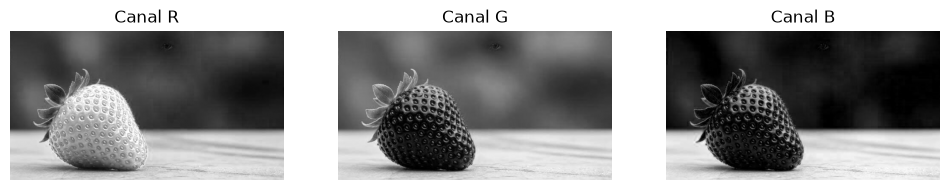

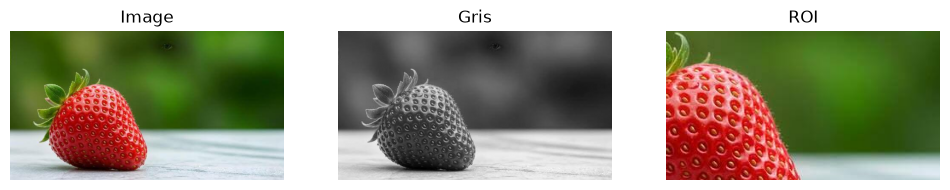

In [9]:
rgb = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)    # Matplotlib attend du RGB
gris = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)
hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
roi = rgb[h//4:3*h//4, w//4:3*w//4].copy()  # copy(): évite le partage de mémoire avec rgb

print("Forme de la ROI :", roi.shape)

# Réduction au quart de chaque dimension (dsize = (largeur, hauteur))
petite = cv.resize(bgr, (w // 4, h // 4), interpolation=cv.INTER_AREA)
print("Forme réduite :", petite.shape)
print("Rapport des nombres de pixels :", (h * w) / (petite.shape[0] * petite.shape[1]))

# Canaux RGB séparés en niveaux de gris
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for i, nom in enumerate(["R", "G", "B"]):
    ax[i].imshow(rgb[..., i], cmap="gray", vmin=0, vmax=255)
    ax[i].set_title(f"Canal {nom}"); ax[i].axis("off")
plt.show()

# Comparaison légendée : image, gris, ROI
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, im, t, cm in zip(ax, [rgb, gris, roi], ["Image", "Gris", "ROI"], [None, "gray", None]):
    a.imshow(im, cmap=cm); a.set_title(t); a.axis("off")
plt.savefig("comparaison.png", dpi=150, bbox_inches="tight")
plt.show()

## Activité 3 – Intensités et histogrammes

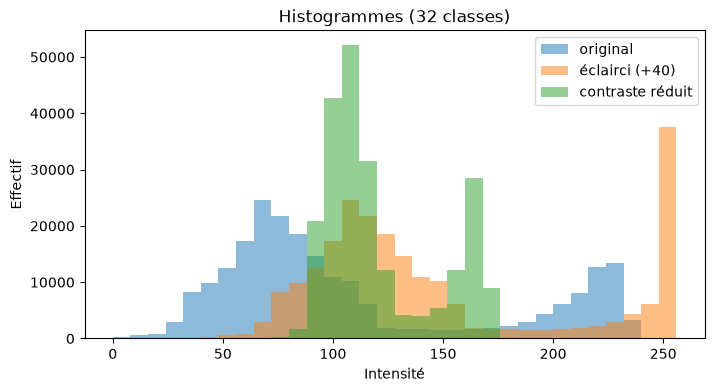

Pixels à 255 : original = 0 | éclairci = 30435
Plage contraste réduit : 78 à 177


In [10]:
clair = np.clip(gris.astype(np.float32) + 40, 0, 255)
clair = clair.astype(np.uint8)

contraste = np.clip(
    0.4 * (gris.astype(np.float32) - 128) + 128, 0, 255
).astype(np.uint8)

plt.figure(figsize=(8, 4))
for im, lab in [(gris, "original"), (clair, "éclairci (+40)"), (contraste, "contraste réduit")]:
    plt.hist(im.ravel(), bins=32, range=(0, 256), alpha=0.5, label=lab)
plt.xlabel("Intensité"); plt.ylabel("Effectif"); plt.legend()
plt.title("Histogrammes (32 classes)")
plt.show()

# Écrêtage : part de pixels saturés à 255 dans la version éclaircie
print("Pixels à 255 : original =", np.count_nonzero(gris == 255),
      "| éclairci =", np.count_nonzero(clair == 255))
print("Plage contraste réduit :", contraste.min(), "à", contraste.max())

## Activité 4 – Quantification sur quatre niveaux

[  0  85 170 255] 224700 224700


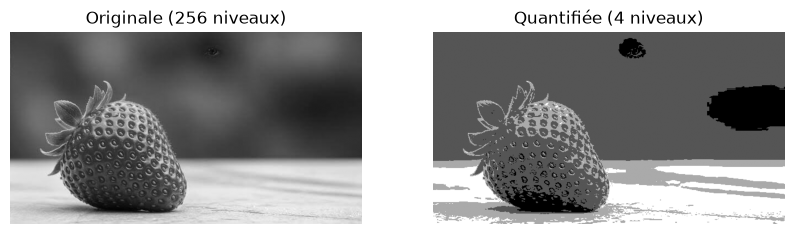

Taille compacte : 56175 octets ( 4.0 x plus petit )


In [11]:
L = 4
q = np.rint(gris.astype(np.float32) * (L - 1) / 255)
q = np.rint(q * 255 / (L - 1)).astype(np.uint8)

print(np.unique(q), q.nbytes, gris.nbytes)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(gris, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Originale (256 niveaux)")
ax[1].imshow(q, cmap="gray", vmin=0, vmax=255);    ax[1].set_title("Quantifiée (4 niveaux)")
for a in ax: a.axis("off")
plt.show()

# Stockage réellement compact sur 2 bits : 4 pixels par octet
idx = (q // 85).astype(np.uint8).ravel()          # valeurs 0..3
pad = (-len(idx)) % 4
idx = np.pad(idx, (0, pad))
compact = (idx[0::4] << 6) | (idx[1::4] << 4) | (idx[2::4] << 2) | idx[3::4]
print("Taille compacte :", compact.nbytes, "octets (", gris.nbytes / compact.nbytes, "x plus petit )")

## Activité 5 – Masque de couleur rouge

Pixels sélectionnés : 14.74 %


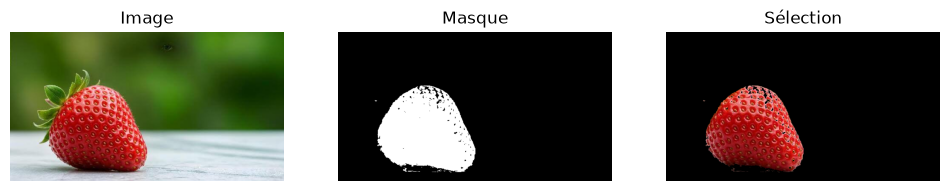

In [12]:
m1 = cv.inRange(hsv, np.array([0, 80, 50], np.uint8),
                np.array([10, 255, 255], np.uint8))
m2 = cv.inRange(hsv, np.array([170, 80, 50], np.uint8),
                np.array([179, 255, 255], np.uint8))
masque = cv.bitwise_or(m1, m2)
selection = cv.bitwise_and(rgb, rgb, mask=masque)
taux = 100 * np.count_nonzero(masque) / masque.size
print(f"Pixels sélectionnés : {taux:.2f} %")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(rgb);                ax[0].set_title("Image")
ax[1].imshow(masque, cmap="gray"); ax[1].set_title("Masque")
ax[2].imshow(selection);          ax[2].set_title("Sélection")
for a in ax: a.axis("off")
plt.show()

In [13]:
# Variation d'un seuil à la fois (ici S minimum) : noter l'effet
def taux_rouge(smin=80, vmin=50, h_haut=10, h_bas=170):
    a = cv.inRange(hsv, np.array([0, smin, vmin], np.uint8), np.array([h_haut, 255, 255], np.uint8))
    b = cv.inRange(hsv, np.array([h_bas, smin, vmin], np.uint8), np.array([179, 255, 255], np.uint8))
    return 100 * np.count_nonzero(cv.bitwise_or(a, b)) / a.size

for smin in (30, 80, 150):
    print(f"S_min = {smin:3d} -> {taux_rouge(smin=smin):.2f} %")

S_min =  30 -> 15.30 %
S_min =  80 -> 14.74 %
S_min = 150 -> 12.25 %


## Activité 6 – Stockage et fichiers

In [14]:
cv.imwrite("copie.png", bgr)
cv.imwrite("qualite90.jpg", bgr, [cv.IMWRITE_JPEG_QUALITY, 90])
cv.imwrite("qualite30.jpg", bgr, [cv.IMWRITE_JPEG_QUALITY, 30])

print(f"{'Fichier':14s} {'Taille fichier (o)':>20s} {'Tableau décodé (o)':>20s} {'Identique ?':>12s}")
for nom in ["copie.png", "qualite90.jpg", "qualite30.jpg"]:
    relu = cv.imread(nom)
    taille_fichier = os.path.getsize(nom)
    identique = np.array_equal(relu, bgr)
    print(f"{nom:14s} {taille_fichier:20d} {relu.nbytes:20d} {str(identique):>12s}")

Fichier          Taille fichier (o)   Tableau décodé (o)  Identique ?
copie.png                    246153               674100         True
qualite90.jpg                 32652               674100        False
qualite30.jpg                 12952               674100        False
